# Análise Descritiva — Instrumento Experimental de Avaliação de Interfaces

**TCC:** "Affordances e Significantes como Estratégias para Aprimoramento da Usabilidade e do Desempenho em Sistemas de Informação"

**Objetivo:** Apresentar indicadores comportamentais observáveis (sucesso, tempo, erros, interações, hover) comparando a Versão A (Experimental) e a Versão B (Controle).

**Observações metodológicas:**
- Esta análise é estritamente **descritiva**. Não são aplicados testes de hipótese inferenciais.
- Os dados consumidos são exclusivamente os **dados processados** (`data/processed/`).
- Nenhum indicador é interpretado como medida de carga cognitiva.
- A leitura dos resultados utiliza verbos como "observou-se", "sugere", "indica", sem afirmações de causalidade.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

CORES = {'A': '#2B6CB0', 'B': '#4A5568'}

PROCESSED_DIR = os.path.join('..', 'data', 'processed')
RAW_DIR = os.path.join('..', 'data', 'raw')
FIGURES_DIR = os.path.join(PROCESSED_DIR, 'figures')

os.makedirs(FIGURES_DIR, exist_ok=True)

%matplotlib inline

print("Setup concluído.")

Setup concluído.


In [2]:
df_metrics = pd.read_csv(os.path.join(PROCESSED_DIR, 'processed_metrics.csv'))
df_summary = pd.read_csv(os.path.join(PROCESSED_DIR, 'processed_metrics_summary.csv'))
df_errors = pd.read_csv(os.path.join(PROCESSED_DIR, 'derived_errors.csv'))
df_raw = pd.read_csv(os.path.join(RAW_DIR, 'raw_events.csv'))
df_raw['timestamp_dt'] = pd.to_datetime(df_raw['timestamp'])

print(f"Arquivos carregados:")
print(f"  - processed_metrics.csv: {len(df_metrics)} linhas")
print(f"  - processed_metrics_summary.csv: {len(df_summary)} linhas")
print(f"  - derived_errors.csv: {len(df_errors)} linhas")
print(f"  - raw_events.csv: {len(df_raw)} linhas (apenas para visualização)")

Arquivos carregados:
  - processed_metrics.csv: 8 linhas
  - processed_metrics_summary.csv: 2 linhas
  - derived_errors.csv: 160 linhas
  - raw_events.csv: 31970 linhas (apenas para visualização)


## 1. Caracterização da Amostra

Composição da amostra: número de participantes, sessões e distribuição do contrabalanceamento (AB vs BA).

In [3]:
n_participantes = df_errors['participant_id'].nunique()
n_sessoes = df_errors['session_id'].nunique()
dist_ordem = df_errors.groupby('condition_order')['participant_id'].nunique().reset_index()
dist_ordem.columns = ['condition_order', 'n_participantes']

print(f"Participantes únicos: {n_participantes}")
print(f"Sessões únicas: {n_sessoes}")
print()
display(dist_ordem)

Participantes únicos: 20
Sessões únicas: 20



,condition_order,n_participantes
0,AB,10
1,BA,10


## 2. Métrica 1 — Taxa de Sucesso

A taxa de sucesso é calculada como `1 - (erros de decisão / total de tarefas)` por condição.
Um erro de decisão ocorre quando a decisão final do participante difere da decisão esperada (`expected_decision`).

In [4]:
display(df_summary[['condition', 'n_participantes', 'taxa_sucesso']])

display(df_metrics[['condition', 'task_id', 'taxa_sucesso']].pivot(
    index='task_id', columns='condition', values='taxa_sucesso'
).reset_index())

,condition,n_participantes,taxa_sucesso
0,A,20,0.60
1,B,20,0.61


condition,task_id,A,B
0,T01,0.9,0.90
1,T02,0.8,0.80
2,T03,0.2,0.25
3,T04,0.5,0.50


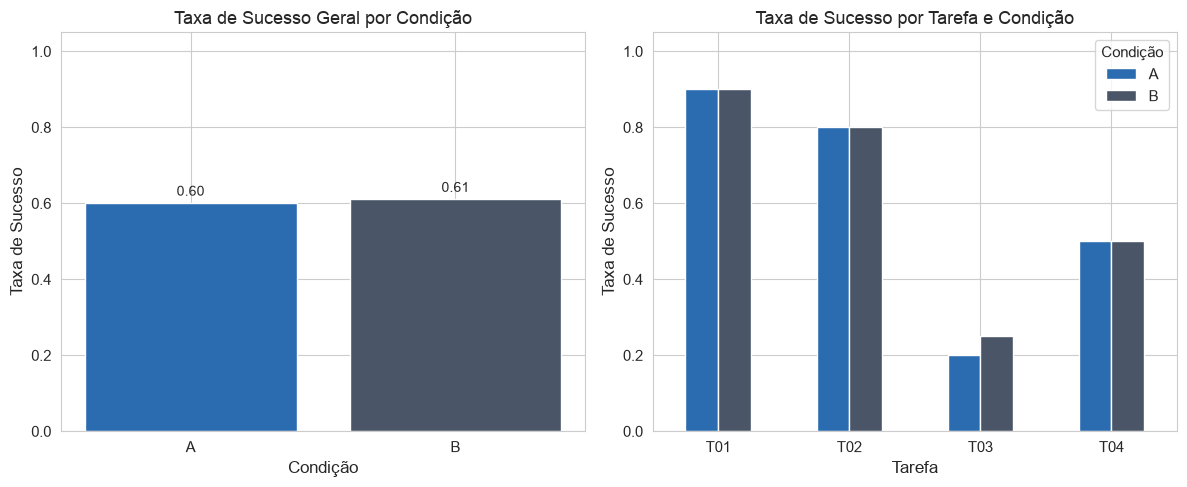

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

geral = df_summary[['condition', 'taxa_sucesso']]
bars1 = axes[0].bar(geral['condition'], geral['taxa_sucesso'],
                    color=[CORES[c] for c in geral['condition']])
axes[0].set_title('Taxa de Sucesso Geral por Condição')
axes[0].set_xlabel('Condição')
axes[0].set_ylabel('Taxa de Sucesso')
axes[0].set_ylim(0, 1.05)
for bar, val in zip(bars1, geral['taxa_sucesso']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.2f}', ha='center', fontsize=10)

pivot = df_metrics[['condition', 'task_id', 'taxa_sucesso']].pivot(
    index='task_id', columns='condition', values='taxa_sucesso'
)
pivot.plot(kind='bar', ax=axes[1], color=[CORES['A'], CORES['B']])
axes[1].set_title('Taxa de Sucesso por Tarefa e Condição')
axes[1].set_xlabel('Tarefa')
axes[1].set_ylabel('Taxa de Sucesso')
axes[1].set_ylim(0, 1.05)
axes[1].legend(title='Condição')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'sucesso_por_condicao.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Métrica 2 — Tempo de Execução

O tempo de cada tarefa é calculado como `timestamp(task_completed) - timestamp(task_started)`.
A distribuição é apresentada via boxplot para permitir leitura de dispersão e outliers.

**Nota:** o boxplot utiliza `raw_events.csv` exclusivamente para visualização da distribuição. Nenhuma nova métrica é derivada.

In [6]:
display(df_summary[['condition', 'tempo_medio_ms', 'tempo_mediano_ms']].rename(columns={
    'tempo_medio_ms': 'Tempo médio (ms)',
    'tempo_mediano_ms': 'Tempo mediano (ms)'
}))

display(df_metrics[['condition', 'task_id', 'tempo_medio_ms', 'tempo_mediano_ms',
                    'tempo_min_ms', 'tempo_max_ms', 'tempo_desvio_padrao_ms']])

,condition,Tempo médio (ms),Tempo mediano (ms)
0,A,17739.21,11840.0
1,B,14344.28,12243.0


,condition,task_id,tempo_medio_ms,tempo_mediano_ms,tempo_min_ms,tempo_max_ms,tempo_desvio_padrao_ms
0,A,T01,24039.75,18770.0,8562.0,69586.0,15713.32
1,A,T02,13276.65,11816.5,4427.0,34569.0,7972.03
2,A,T03,23195.35,9881.0,3751.0,234300.0,50263.09
3,A,T04,10445.10,9327.5,2800.0,25930.0,6121.53
4,B,T01,20015.35,16683.5,9043.0,35583.0,8460.72
5,B,T02,14163.35,11154.5,3006.0,37191.0,10161.06
6,B,T03,11773.85,12240.5,4056.0,31612.0,6392.16
7,B,T04,11424.55,9063.5,4252.0,39325.0,8372.99


/var/folders/4s/57s2s8cn41n5210_0gqhh4g80000gn/T/ipykernel_60392/3495603853.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=durations_viz, x='condition', y='duration_s', palette=CORES, order=['A', 'B'])


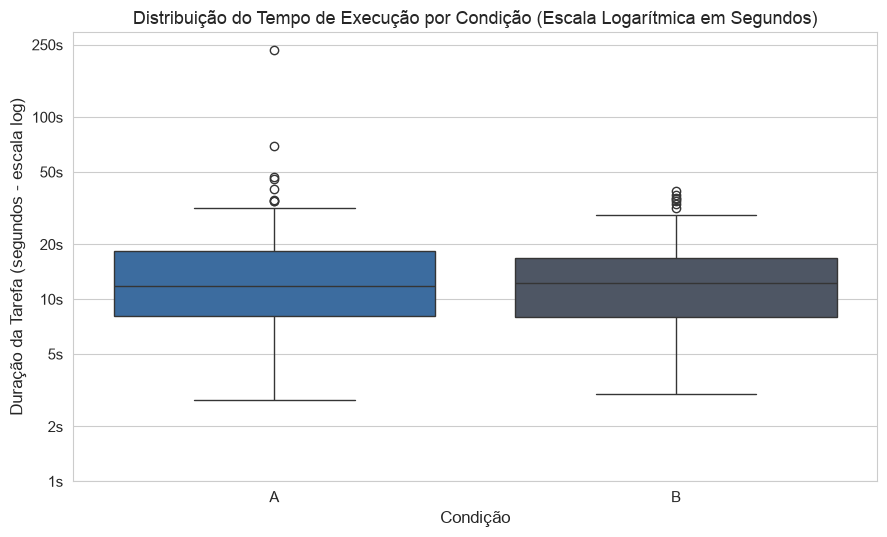

In [7]:
task_starts = df_raw[df_raw['event_type'] == 'task_started'][['session_id', 'task_id', 'condition', 'timestamp_dt']]
task_ends = df_raw[df_raw['event_type'] == 'task_completed'][['session_id', 'task_id', 'condition', 'timestamp_dt']]
durations_viz = pd.merge(
    task_starts, task_ends,
    on=['session_id', 'task_id', 'condition'],
    suffixes=('_start', '_end')
)
durations_viz['duration_s'] = (durations_viz['timestamp_dt_end'] - durations_viz['timestamp_dt_start']).dt.total_seconds()

plt.figure(figsize=(9, 5.5))
ax = sns.boxplot(data=durations_viz, x='condition', y='duration_s', palette=CORES, order=['A', 'B'])
plt.yscale('log')
plt.title('Distribuição do Tempo de Execução por Condição (Escala Logarítmica em Segundos)')
plt.xlabel('Condição')
plt.ylabel('Duração da Tarefa (segundos - escala log)')

from matplotlib.ticker import ScalarFormatter
ax.yaxis.set_major_formatter(ScalarFormatter())
plt.yticks([1, 2, 5, 10, 20, 50, 100, 250], ['1s', '2s', '5s', '10s', '20s', '50s', '100s', '250s'])

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'tempo_boxplot.png'), dpi=150, bbox_inches='tight')
plt.show()

<Figure size 1000x500 with 0 Axes>

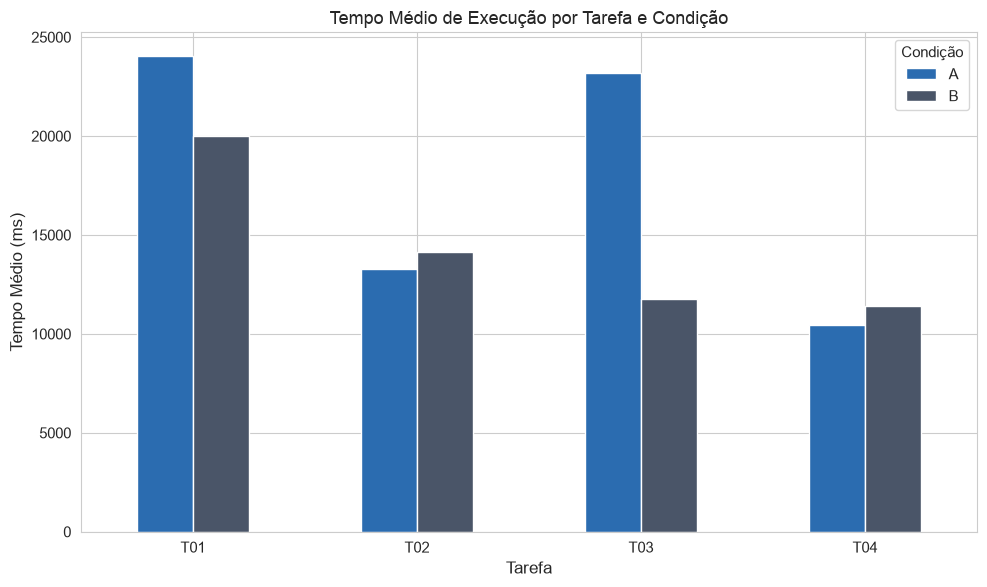

In [8]:
pivot_tempo = df_metrics[['condition', 'task_id', 'tempo_medio_ms']].pivot(
    index='task_id', columns='condition', values='tempo_medio_ms'
)

plt.figure(figsize=(10, 5))
pivot_tempo.plot(kind='bar', color=[CORES['A'], CORES['B']])
plt.title('Tempo Médio de Execução por Tarefa e Condição')
plt.xlabel('Tarefa')
plt.ylabel('Tempo Médio (ms)')
plt.legend(title='Condição')
plt.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'tempo_por_tarefa.png'), dpi=150, bbox_inches='tight')
plt.show()

## 4. Métrica 3 — Erros por Tipo

Três tipos de erro são registrados conforme as definições operacionais:
- **Erro de decisão:** decisão final ≠ decisão esperada.
- **Erro de navegação:** clique em elemento fora dos alvos válidos da tarefa.
- **Erro de omissão:** elemento obrigatório não recebeu interação (hover ou clique).

,condition,n_erros_decisao,n_erros_navegacao,n_erros_omissao
0,A,32,21,0
1,B,31,19,14


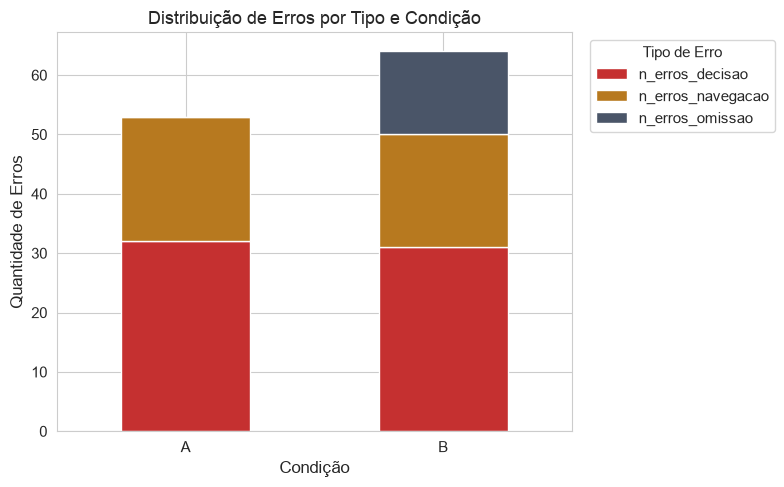

In [9]:
tabela_erros = df_summary[['condition', 'n_erros_decisao', 'n_erros_navegacao', 'n_erros_omissao']]
display(tabela_erros)

erros_plot = tabela_erros.set_index('condition')
erros_plot.plot(kind='bar', stacked=True,
                color=['#C53030', '#B7791F', '#4A5568'],
                figsize=(8, 5))
plt.title('Distribuição de Erros por Tipo e Condição')
plt.xlabel('Condição')
plt.ylabel('Quantidade de Erros')
plt.legend(title='Tipo de Erro', bbox_to_anchor=(1.02, 1))
plt.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'erros_por_tipo.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Métricas Secundárias

Indicadores complementares de interação:
- Total de cliques registrados.
- Total de alterações de decisão (troca entre botões antes da confirmação).
- Tempo médio de hover sobre elementos com `element_id`.

,condition,n_interacoes_total,n_alteracoes_decisao,tempo_medio_hover_ms
0,A,179,1,1172.23
1,B,183,3,1007.68


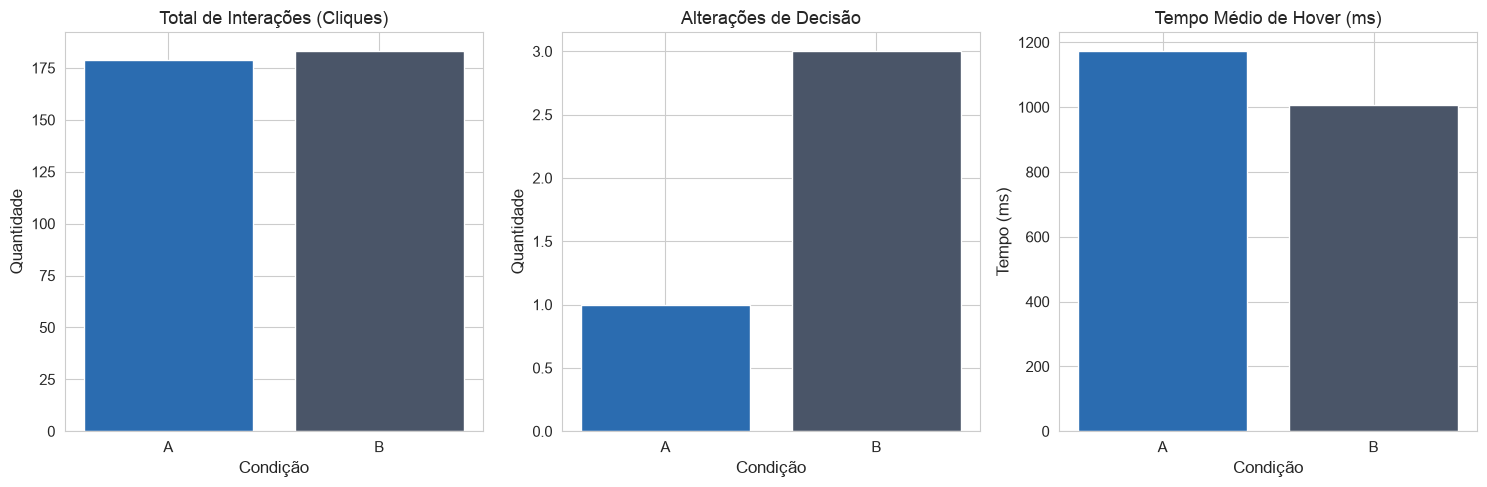

In [10]:
display(df_summary[['condition', 'n_interacoes_total', 'n_alteracoes_decisao', 'tempo_medio_hover_ms']])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].bar(df_summary['condition'], df_summary['n_interacoes_total'],
            color=[CORES[c] for c in df_summary['condition']])
axes[0].set_title('Total de Interações (Cliques)')
axes[0].set_xlabel('Condição')
axes[0].set_ylabel('Quantidade')

axes[1].bar(df_summary['condition'], df_summary['n_alteracoes_decisao'],
            color=[CORES[c] for c in df_summary['condition']])
axes[1].set_title('Alterações de Decisão')
axes[1].set_xlabel('Condição')
axes[1].set_ylabel('Quantidade')

axes[2].bar(df_summary['condition'], df_summary['tempo_medio_hover_ms'],
            color=[CORES[c] for c in df_summary['condition']])
axes[2].set_title('Tempo Médio de Hover (ms)')
axes[2].set_xlabel('Condição')
axes[2].set_ylabel('Tempo (ms)')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'metricas_secundarias.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6. Discussão dos Resultados

> **Atenção:** esta seção é um **template de leitura**. Os valores numéricos devem ser preenchidos pelo pesquisador após a execução do notebook com os dados reais da coleta.

Observou-se que a taxa de sucesso na Versão A (Experimental) foi de **[X]**, enquanto na Versão B (Controle) foi de **[Y]**. Essa diferença de **[Z] pontos percentuais** sugere que a aplicação sistemática de affordances e significantes pode estar associada a uma maior precisão nas decisões.

O tempo médio de execução foi de **[X] ms** na Versão A e **[Y] ms** na Versão B, uma diferença de **[Z] ms**. Esse indicador sugere que a organização modular e a hierarquia visual podem ter facilitado a escaneabilidade das informações.

Em relação aos erros de navegação, a Versão B apresentou **[Z]** erros a mais que a Versão A, o que pode indicar que a ausência de hierarquia visual nos botões de decisão contribuiu para cliques em elementos fora do esperado.

Os erros de omissão foram **[comparação]**, sugerindo que a disposição dos elementos obrigatórios pode ter influenciado a atenção dos participantes.

O número de alterações de decisão foi **[comparação]**, o que pode indicar maior ou menor segurança na escolha inicial, dependendo do sentido da diferença.

**Limitações:**
- A amostra é pequena (N=[X]) e de natureza exploratória.
- Não foram aplicados testes de hipótese inferenciais.
- Os resultados não permitem afirmações de causalidade.
- A ordem de apresentação das condições (AB vs BA) pode ter introduzido efeitos de aprendizagem ou fadiga, ainda que o contrabalanceamento tenha sido aplicado.

**Próximos passos:**
- Ampliar a amostra para permitir análises inferenciais.
- Investigar a relação entre tempo de hover e precisão da decisão.
- Explorar a interação entre condição e ordem de apresentação.

## 7. Análise por Participante (Within-Subject)

Como o desenho é **within-subject**, cada participante passou pelas duas condições (A e B). A tabela abaixo compara o desempenho **de cada participante consigo mesmo**, o que permite avaliar se o efeito observado nas médias gerais é **consistente** ou se está concentrado em poucos voluntários.

Os dados desta seção vêm do arquivo `per_participant.csv` gerado pelo script `processing/per_participant.py`.

In [11]:
df_pc = pd.read_csv(os.path.join(PROCESSED_DIR, 'per_participant.csv'))

colunas_exibir = [
    'participant_id',
    'taxa_sucesso_A', 'taxa_sucesso_B', 'delta_taxa_sucesso', 'melhorou_em_sucesso',
    'tempo_medio_A_ms', 'tempo_medio_B_ms', 'delta_tempo_ms',
    'erros_total_A', 'erros_total_B', 'delta_erros_total'
]
display(df_pc[colunas_exibir])

,participant_id,taxa_sucesso_A,taxa_sucesso_B,delta_taxa_sucesso,melhorou_em_sucesso,tempo_medio_A_ms,tempo_medio_B_ms,delta_tempo_ms,erros_total_A,erros_total_B,delta_erros_total
0,P01,0.50,0.50,0.00,empate,20787.25,8844.50,-11942.75,4,3,-1
1,P02,0.50,0.50,0.00,empate,7311.75,6938.00,-373.75,14,8,-6
2,P03,0.50,0.50,0.00,empate,13611.50,6411.00,-7200.50,2,3,1
3,P04,0.75,0.75,0.00,empate,75055.00,15686.25,-59368.75,1,5,4
4,P05,0.50,0.50,0.00,empate,21161.25,5319.25,-15842.00,2,3,1
5,P06,0.50,0.50,0.00,empate,6092.75,32375.25,26282.50,2,3,1
6,P07,0.75,0.75,0.00,empate,13220.75,11325.75,-1895.00,1,2,1
7,P08,0.25,0.25,0.00,empate,6296.25,13873.50,7577.25,3,4,1
8,P09,0.50,0.75,0.25,B melhor,18304.00,14610.75,-3693.25,3,2,-1
9,P10,1.00,1.00,0.00,empate,10324.00,18534.75,8210.75,0,1,1


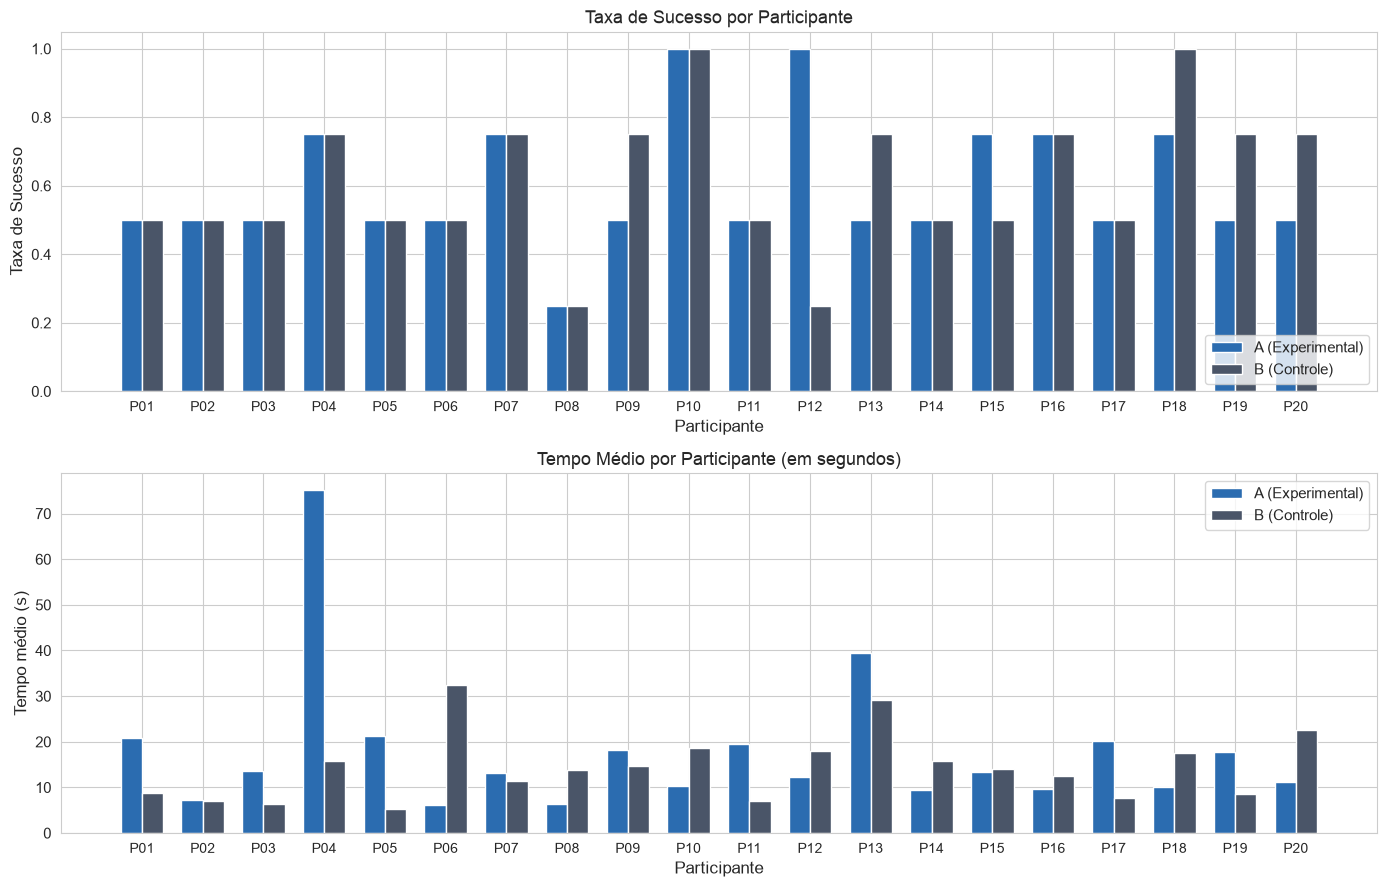

In [12]:
# Gráfico empilhado: sucesso e tempo (em segundos) por participante (A vs B)
df_pc_sorted = df_pc.sort_values('participant_id').reset_index(drop=True)
x = range(len(df_pc_sorted))
largura = 0.35

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# 1º Gráfico (Topo): Taxa de Sucesso
axes[0].bar([i - largura/2 for i in x], df_pc_sorted['taxa_sucesso_A'], width=largura, color=CORES['A'], label='A (Experimental)')
axes[0].bar([i + largura/2 for i in x], df_pc_sorted['taxa_sucesso_B'], width=largura, color=CORES['B'], label='B (Controle)')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(df_pc_sorted['participant_id'], fontsize=10)
axes[0].set_title('Taxa de Sucesso por Participante')
axes[0].set_xlabel('Participante')
axes[0].set_ylabel('Taxa de Sucesso')
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc='lower right')
axes[0].tick_params(axis='x', rotation=0)

# 2º Gráfico (Base): Tempo Médio (s)
tempo_A_s = df_pc_sorted['tempo_medio_A_ms'] / 1000.0
tempo_B_s = df_pc_sorted['tempo_medio_B_ms'] / 1000.0

axes[1].bar([i - largura/2 for i in x], tempo_A_s, width=largura, color=CORES['A'], label='A (Experimental)')
axes[1].bar([i + largura/2 for i in x], tempo_B_s, width=largura, color=CORES['B'], label='B (Controle)')
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(df_pc_sorted['participant_id'], fontsize=10)
axes[1].set_title('Tempo Médio por Participante (em segundos)')
axes[1].set_xlabel('Participante')
axes[1].set_ylabel('Tempo médio (s)')
axes[1].legend(loc='upper right')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'within_subject_por_participante.png'), dpi=150, bbox_inches='tight')
plt.show()

### 7.1 Leitura dos resultados por participante

> **Atenção:** esta seção é um **template de leitura**. Os valores numéricos devem ser preenchidos pelo pesquisador após a execução do notebook com os dados reais da coleta.

Para cada participante, comparou-se o desempenho entre as duas condições. Observou-se que:

- **[X] participantes** apresentaram taxa de sucesso igual ou superior em **A**.
- **[Y] participantes** apresentaram taxa de sucesso igual ou superior em **B**.
- **[Z] participantes** apresentaram empate.

Esse padrão sugere que o efeito observado nas médias gerais **[é consistente entre os participantes / está concentrado em um subconjunto de participantes]**, o que **[reforça / relativiza]** a leitura dos resultados agregados.

Em relação ao tempo médio por participante, observou-se que **[X] participantes** foram mais rápidos em A e **[Y] participantes** foram mais rápidos em B, indicando que a diferença de tempo **[foi consistente / variou bastante entre participantes]**.

**Nota metodológica:** como o desenho é within-subject, a comparação por participante é a unidade de análise mais natural para este experimento. Ela permite avaliar a consistência do efeito sem depender exclusivamente de médias gerais, que podem ser distorcidas por valores extremos em amostras pequenas.